# Frequência de amostragem e frequência de Nyquist

Ideias principais:

* Este notebook apresenta gráficos de sinais digitais com frequências abaixo e acima da frequência de Nyquist.
* Sinais com frequências acima da frequência de Nyquist podem desaparecer ou ser representados incorretamente, pois não há amostras suficientes por ciclo.

### Criar um vetor de tempo

In [9]:
# -- Importar algumas bibliotecas Python
import numpy as np
import matplotlib.pyplot as plt

# -- Definir a frequência de amostragem, fs = 20 Hz
fs = 20.

# -- Definir as amostras de tempo para 1 segundo de dados
# -- A função "arange" cria um array de números
time = np.arange(0,1.,1./fs)

# -- Exibir o vetor de tempo
print(time)

print("Número de amostras, N =", len(time))
print("Duração total, T(s):", len(time) / fs) 

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95]
Número de amostras, N = 20
Duração total, T(s): 1.0


### Sinal de 2 Hz

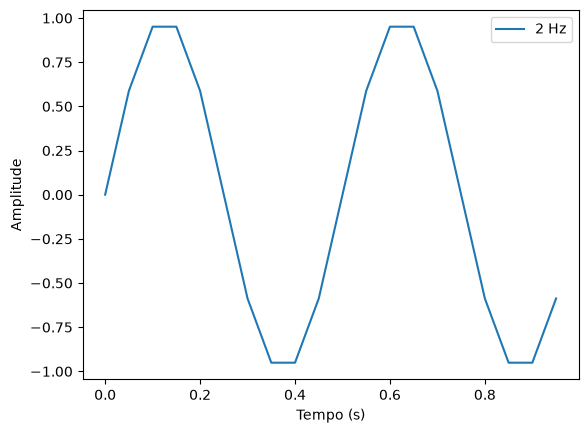

In [10]:
# -- Gerar uma onda senoidal de 2 Hz e representá-la graficamente
f = 2   # -- Sinal de 2 Hz
sin2 = np.sin(2*np.pi*f*time)

# -- Representar a onda senoidal
plt.plot(time, sin2, label='2 Hz')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.legend()

## Sinal de 5 Hz

O que acontece se tentarmos representar graficamente um sinal na frequência de Nyquist?

**Observação didática:** Para a frequência de amostragem utilizada aqui, $f_s = 20\,\mathrm{Hz}$, a frequência de Nyquist é $10\,\mathrm{Hz}$. Portanto, o sinal de 5 Hz do próximo exemplo está abaixo desse limite; o exemplo de 10 Hz aparece em seguida.

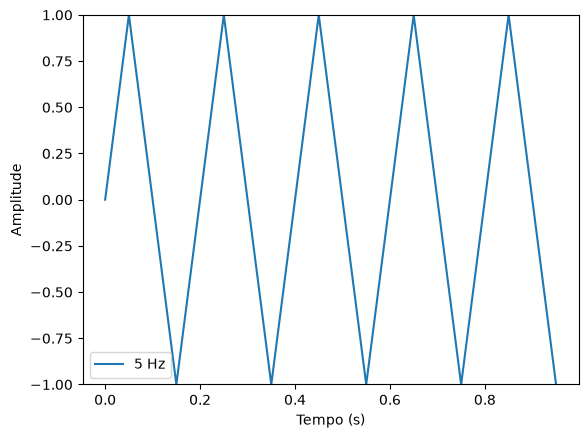

In [11]:
f = 5  # Sinal de 5 Hz
sin5 = np.sin(2*np.pi*f*time)

plt.plot(time, sin5, label='5 Hz')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.ylim(-1,1)
plt.legend()

## Sinal de 10 Hz (na frequência de Nyquist)

(-1.0, 1.0)

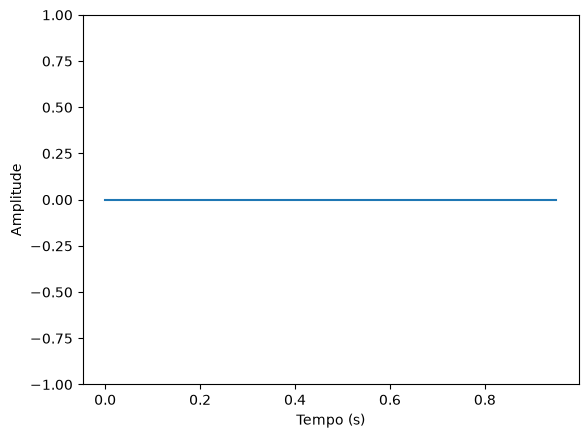

In [13]:
# -- Tentar representar um sinal na frequência de Nyquist
# -- Dica: isso não funciona como esperado, pois não há amostras suficientes
# -- para reconstruir de maneira inequívoca a forma da onda.

f = 10
sin10 = np.sin(2*np.pi*f*time)

plt.plot(time, sin10)
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.ylim(-1,1)

Quando $f=f_s/2$, existem apenas duas amostras por período. Dependendo da fase da onda, essas amostras podem ser todas nulas, como ocorreu com o seno, ou alternar entre valores positivos e negativos, como no cosseno. 

Portanto, amostrar exatamente na frequência de Nyquist não garante a reconstrução inequívoca de uma senoide de fase desconhecida. Para evitar essa situação, utiliza-se a condição estrita.

Precisamos considerar não apenas a frequência do sinal, mas também os instantes em que realizamos as medições.

[ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.
  1. -1.]


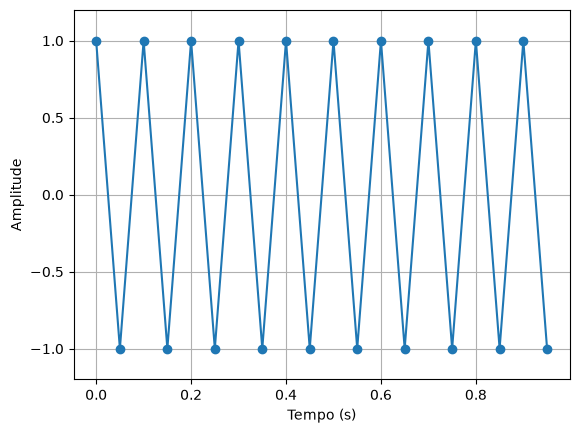

In [14]:
f = 10
cos10 = np.cos(2*np.pi*f*time)

print(cos10)

plt.plot(time, cos10, 'o-')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.ylim(-1.2, 1.2)
plt.grid()

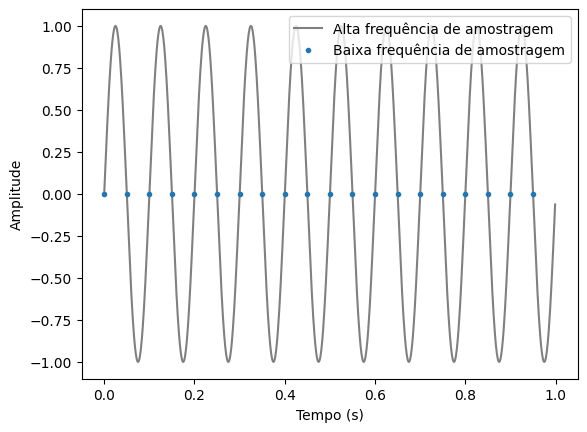

In [5]:
# -- Por fim, para entender o que está acontecendo, vamos representar
# -- o sinal de 10 Hz com frequências de amostragem baixa e alta

fs_better = 1000
time_better = np.arange(0,1, 1/fs_better)

sin10_better = np.sin(2*np.pi*f*time_better)

plt.plot(time_better, sin10_better, 'grey', label='Alta frequência de amostragem')
plt.plot(time, sin10, '.', label='Baixa frequência de amostragem')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.legend(loc=1)

Portanto, nesse exemplo, não alteramos a frequência física da onda (10 Hz). 
Alteramos apenas a frequência com que observamos ou registramos seus valores.

O gráfico compara duas representações do mesmo sinal: uma com amostragem insuficiente para determinar sua fase e amplitude de maneira inequívoca, 
e outra com amostragem suficientemente alta para representar sua forma de onda.

### Questões de verificação

1. Qual é a frequência de amostragem do vetor de tempo criado na primeira célula de código?
2. Quantas amostras existem em 1 segundo de dados?
3. Qual é a frequência de Nyquist para essa frequência de amostragem?
4. Quantas amostras por ciclo existem para o sinal de 5 Hz?
5. Por que o sinal de 10 Hz desaparece? Você consegue explicar esse comportamento?